# Feature Importance for Explainable AI (XAI)

In [ ]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 120

In [ ]:
# preprocessed features
EDA_CSV = "eda_features_60.csv"
IBI_CSV = "ibi_features_60.csv"

# saved models
MODEL_PATH = "rf_uq_model_60.pkl"
SCALER_PATH = "rf_scaler.save"

FEATURE_COLUMNS = [
    'EDA_Tonic_SD','SCR_Peaks_Amplitude_Mean','SCR_Peaks_N',
    'eda_kurtosis','eda_max','eda_mean','eda_min','eda_range',
    'eda_skewness','eda_std',
    'ibi_max','ibi_mean','ibi_median','ibi_min','ibi_range','ibi_std'
]

In [ ]:
eda = pd.read_csv(EDA_CSV)
ibi = pd.read_csv(IBI_CSV)

data = pd.merge(eda, ibi, on=["subject", "label", "window"])

X = data[FEATURE_COLUMNS]
y = data["label"]

print("Samples:", len(X))

Samples: 349


In [ ]:
# load saved models
model = joblib.load(MODEL_PATH)
scaler = joblib.load(SCALER_PATH)

X_scaled = scaler.transform(X)

explainer = shap.TreeExplainer(model)
shap_exp = explainer(X_scaled)

print("SHAP shape:", shap_exp.values.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.1 when using version 1.6.1. This might lead to b

SHAP shape: (349, 16, 2)


In [ ]:
if shap_exp.values.ndim == 3:
    shap_calm = shap_exp.values[:, :, 0]
    shap_stress = shap_exp.values[:, :, 1]
else:
    shap_calm = shap_exp.values
    shap_stress = shap_exp.values

print("Calm SHAP shape:", shap_calm.shape)
print("Stress SHAP shape:", shap_stress.shape)

Calm SHAP shape: (349, 16)
Stress SHAP shape: (349, 16)


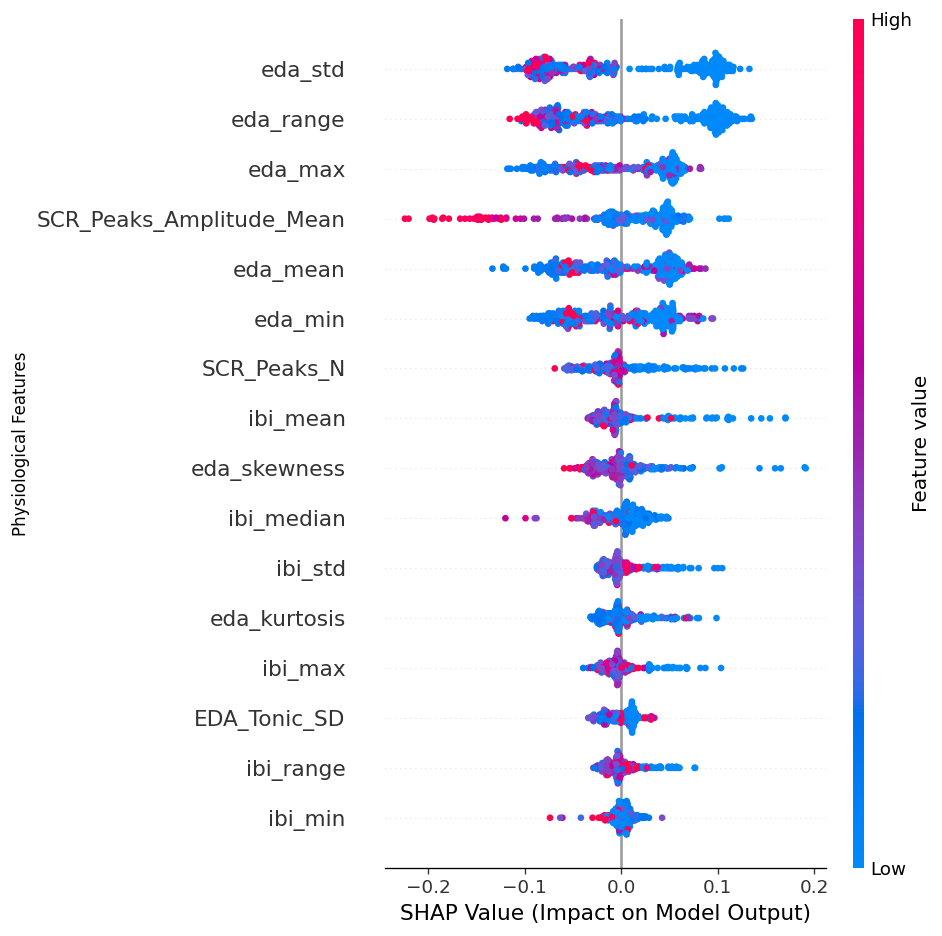

In [ ]:
# Summary Dot Plot for Calm
shap.summary_plot(shap_calm, X, show=False)
plt.xlabel("SHAP Value (Impact on Model Output)")
plt.ylabel("Physiological Features")
plt.tight_layout()
plt.show()

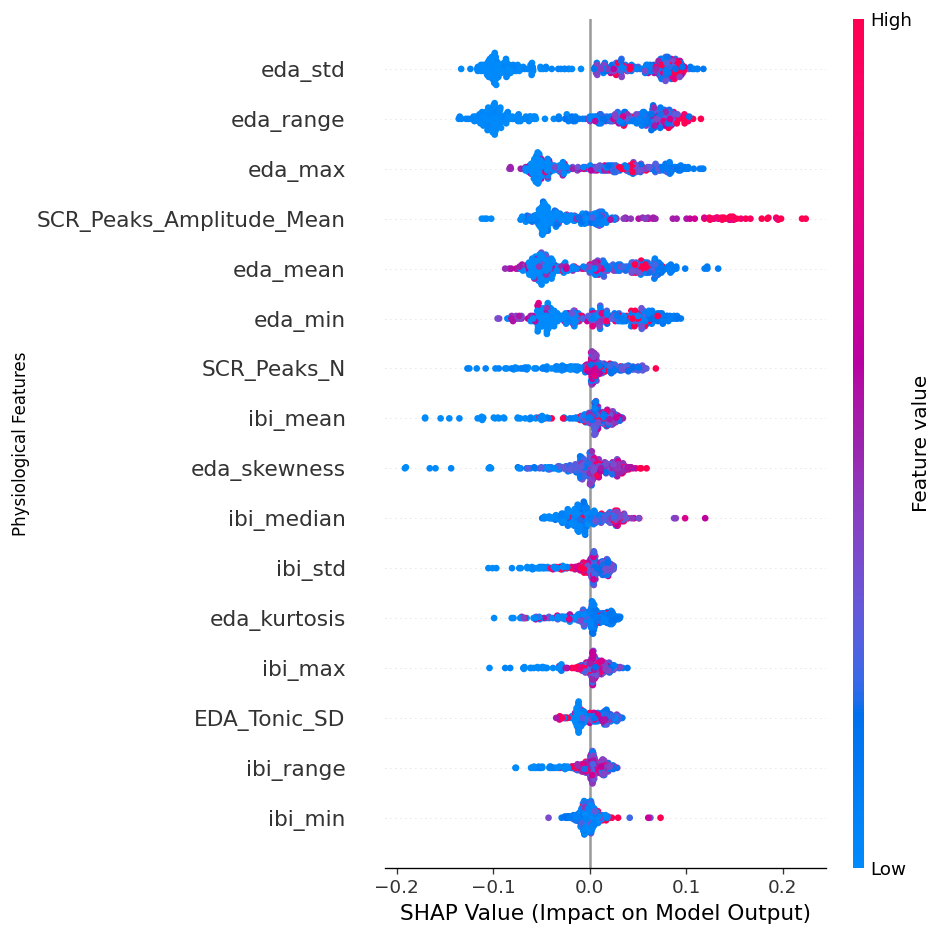

In [ ]:
# Summary Dot Plot for Stress
shap.summary_plot(shap_stress, X, show=False)
plt.xlabel("SHAP Value (Impact on Model Output)")
plt.ylabel("Physiological Features")
plt.tight_layout()
plt.show()

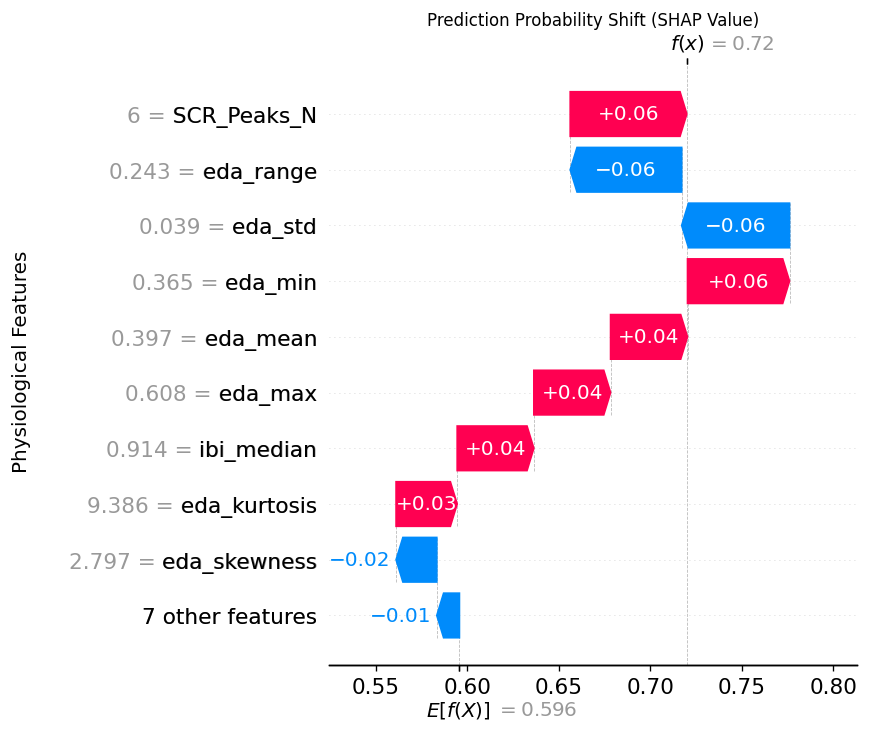

In [ ]:
# Waterfall plot for Calm
idx_calm = np.where(y == 'baseline')[0][0]

exp_calm = shap.Explanation(
    values=shap_calm[idx_calm],
    base_values=shap_exp.base_values[idx_calm][0]
        if shap_exp.base_values.ndim == 2
        else shap_exp.base_values[idx_calm],
    data=X.iloc[idx_calm].values,
    feature_names=FEATURE_COLUMNS
)

shap.plots.waterfall(exp_calm, show=False)

fig = plt.gcf()
plt.xlabel("Prediction Probability Shift (SHAP Value)")
fig.text(0.02, 0.5, "Physiological Features", va='center', rotation='vertical', fontsize=12)
plt.subplots_adjust(left=0.35)
plt.show()

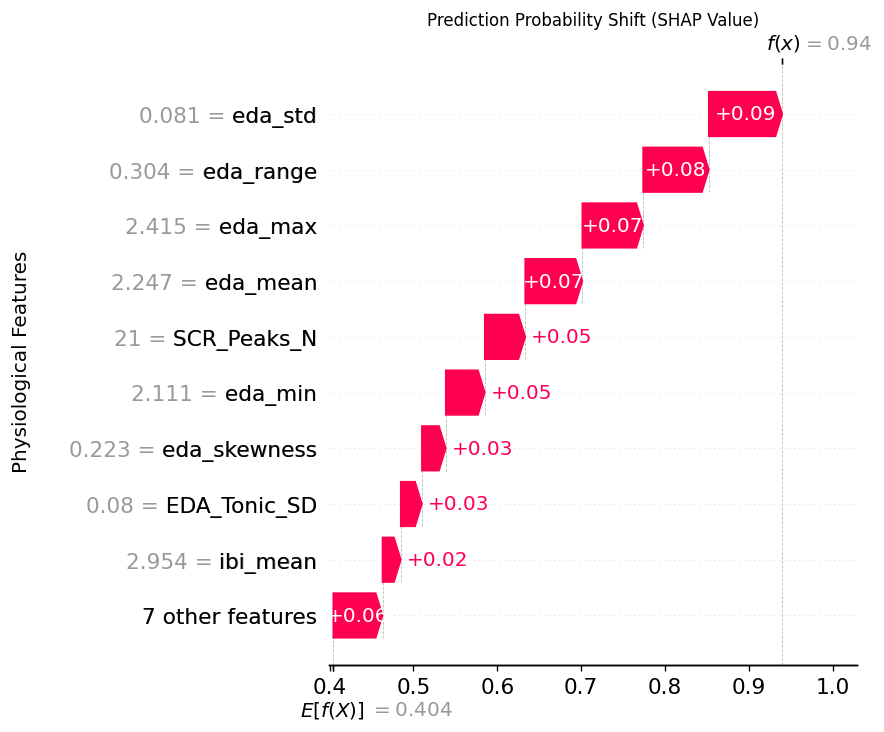

In [ ]:
# Waterfall plot for Stress
idx_stress = np.where(y == 'stress')[0][0]

exp_stress = shap.Explanation(
    values=shap_stress[idx_stress],
    base_values=shap_exp.base_values[idx_stress][1]
        if shap_exp.base_values.ndim == 2
        else shap_exp.base_values[idx_stress],
    data=X.iloc[idx_stress].values,
    feature_names=FEATURE_COLUMNS
)

shap.plots.waterfall(exp_stress, show=False)

fig = plt.gcf()
plt.xlabel("Prediction Probability Shift (SHAP Value)")
fig.text(0.02, 0.5, "Physiological Features", va='center', rotation='vertical', fontsize=12)
plt.subplots_adjust(left=0.35)
plt.show()

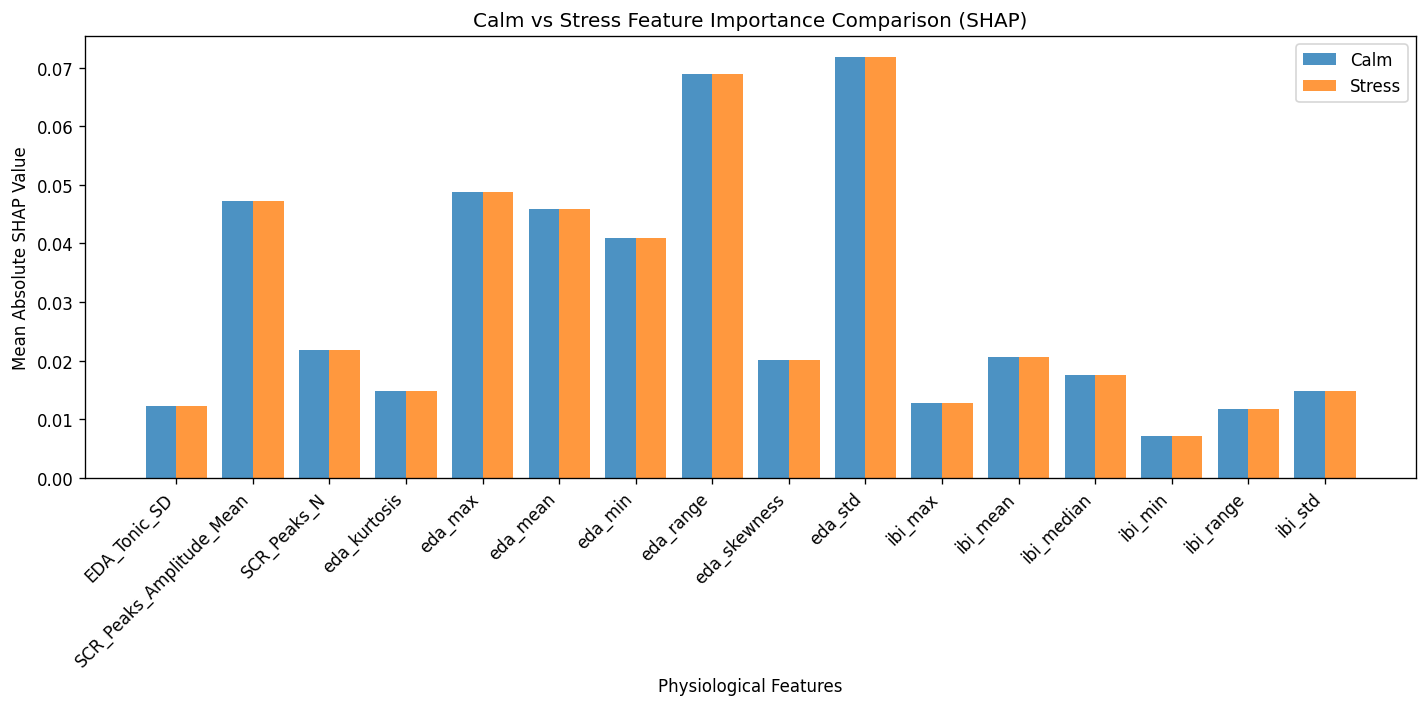

In [ ]:
# mean absolute importance per feature
calm_importance = np.mean(np.abs(shap_calm), axis=0)
stress_importance = np.mean(np.abs(shap_stress), axis=0)

features = FEATURE_COLUMNS
x = np.arange(len(features))

plt.figure(figsize=(12, 6))

plt.bar(x - 0.2, calm_importance, width=0.4, label="Calm", alpha=0.8)
plt.bar(x + 0.2, stress_importance, width=0.4, label="Stress", alpha=0.8)

plt.xticks(x, features, rotation=45, ha="right")
plt.xlabel("Physiological Features")
plt.ylabel("Mean Absolute SHAP Value")
plt.title("Calm vs Stress Feature Importance Comparison (SHAP)")
plt.legend()

plt.tight_layout()
plt.show()

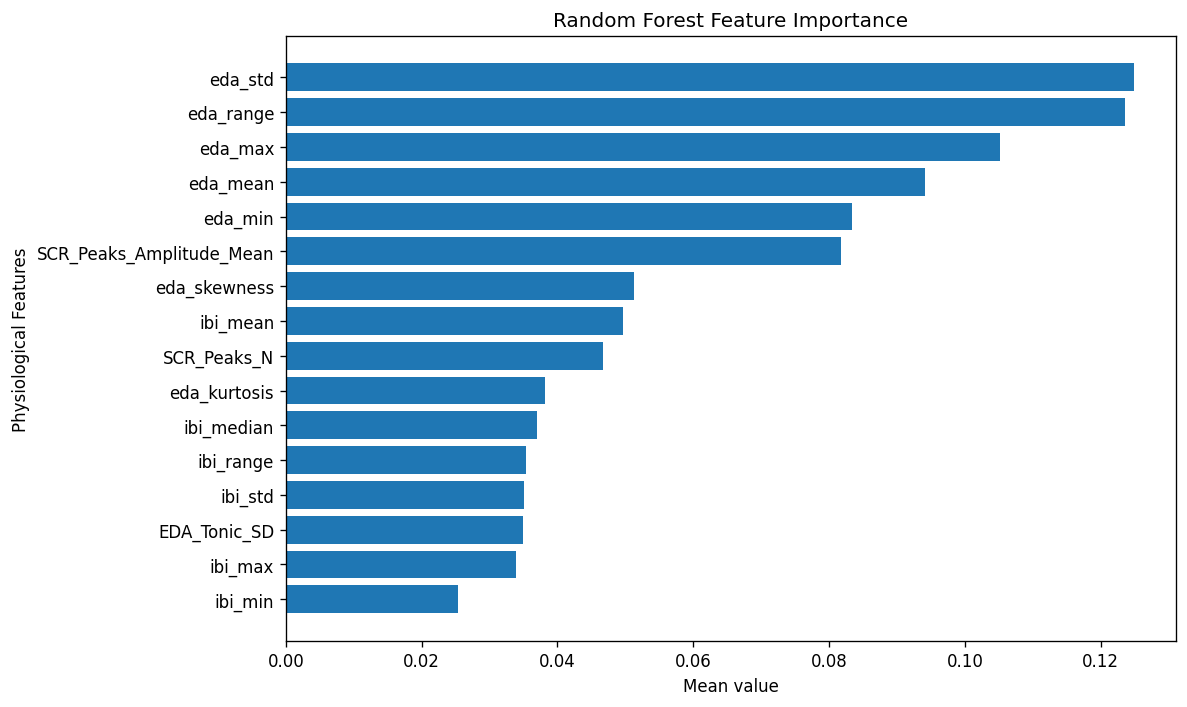

In [ ]:
# Global Feature Importantance 
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()

plt.xlabel("Mean value")
plt.ylabel("Physiological Features")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()